In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
import os

folder_gambar = '/content/drive/MyDrive/PCVK/Gambar'
print('Folder ditemukan:', os.path.isdir(folder_gambar))
if os.path.isdir(folder_gambar):
    print('Isi folder:', os.listdir(folder_gambar))
else:
    print('Buat/unggah folder PCVK/Images di Google Drive, lalu jalankan sel ini lagi.')

Folder ditemukan: True
Isi folder: ['ktm_lama.jpg', '.ipynb_checkpoints', 'foto_aktivitas.jpeg', 'couple.jpg', 'KTP.jpg', 'house.jpg', 'buah.jpg', 'gedung.jpg', 'bola.jpg', 'messi_neymar.jpg', 'house_night.jpg', 'crayfish.png', 'sudoku-original.jpg', 'lena_gs_lc2.jpg', 'plat_nomer.jpg']


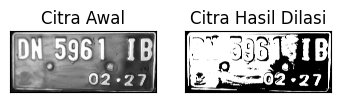

In [25]:
# Dilasi tanpa library

def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_d is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/. Periksa nama file pada output BAGIAN PEMERIKSAAN FILE.")
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


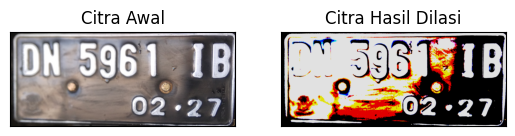

In [26]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

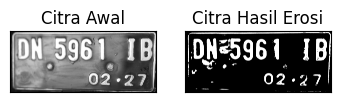

In [27]:
# Erosi Tanpa Library

def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_e is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

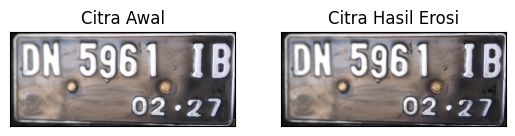

In [29]:
# EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg')
if img is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Gambar/.")
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB)), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

In [ ]:
img_o = cv2.imread('/content/drive/MyDrive/PCVK/Gambar/plat_nomer.jpg', 0)
if img_o is None:
    raise FileNotFoundError("Pastikan file 'plat nomer.jpg' ada di /content/drive/MyDrive/PCVK/Images/.")
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()